<a href="https://colab.research.google.com/github/EsatovinVictoria/ML_Semester5_EsatovinEbenhaezerVictoria/blob/main/Pertemuan_6/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas

Langkah 1 - Menjalankan Kode pada Google Colab

In [ ]:
!pip install annoy hnswlib faiss-cpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 6.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520038 sha256=7c0d653c0c42e32a99f79447173b0b880733fda2179fa48360fcb49d6014460a
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


In [ ]:
!pip install hnswlib

In [ ]:
!pip install faiss-cpu

In [ ]:
import numpy as np
import time

from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss

print("Semua library berhasil di-import")

Semua library berhasil di-import


In [ ]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000
d = 128

X = np.random.random(
    (n_samples, d)
).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10

# -------------------------------
# Exact NN
# -------------------------------
start = time.time()

nn = NearestNeighbors(
    n_neighbors=k,
    algorithm='brute',
    metric='euclidean'
)

nn.fit(X_scaled)

dist_exact, idx_exact = nn.kneighbors(X_scaled)

time_exact = time.time() - start

print(f"Exact NN done in {time_exact:.3f} s")


# -------------------------------
# Annoy
# -------------------------------
start = time.time()

f = X_scaled.shape[1]

index_annoy = AnnoyIndex(
    f,
    'euclidean'
)

for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)

index_annoy.build(10)

idx_annoy = [
    index_annoy.get_nns_by_vector(v, k)
    for v in X_scaled
]

time_annoy = time.time() - start

print(f"Annoy done in {time_annoy:.3f} s")


# -------------------------------
# HNSW
# -------------------------------
start = time.time()

p_hnsw = hnswlib.Index(
    space='l2',
    dim=d
)

p_hnsw.init_index(
    max_elements=n_samples,
    ef_construction=200,
    M=16
)

p_hnsw.add_items(X_scaled)

p_hnsw.set_ef(200)

idx_hnsw, _ = p_hnsw.knn_query(
    X_scaled,
    k=k
)

time_hnsw = time.time() - start

print(f"HNSW done in {time_hnsw:.3f} s")


# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()

quantizer = faiss.IndexFlatL2(d)

index_faiss = faiss.IndexIVFFlat(
    quantizer,
    d,
    100,
    faiss.METRIC_L2
)

index_faiss.train(X_scaled)
index_faiss.add(X_scaled)

index_faiss.nprobe = 10

_, idx_faiss = index_faiss.search(
    X_scaled,
    k
)

time_faiss = time.time() - start

print(f"FAISS IVF done in {time_faiss:.3f} s")


# -------------------------------
# Ringkasan
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")

print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 1.358 s
Annoy done in 0.689 s
HNSW done in 7.294 s
FAISS IVF done in 0.926 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.358
Annoy    : 0.689
HNSW     : 7.294
FAISS    : 0.926


Langkah 2 - Menjalankan Kode pada PyDroid3 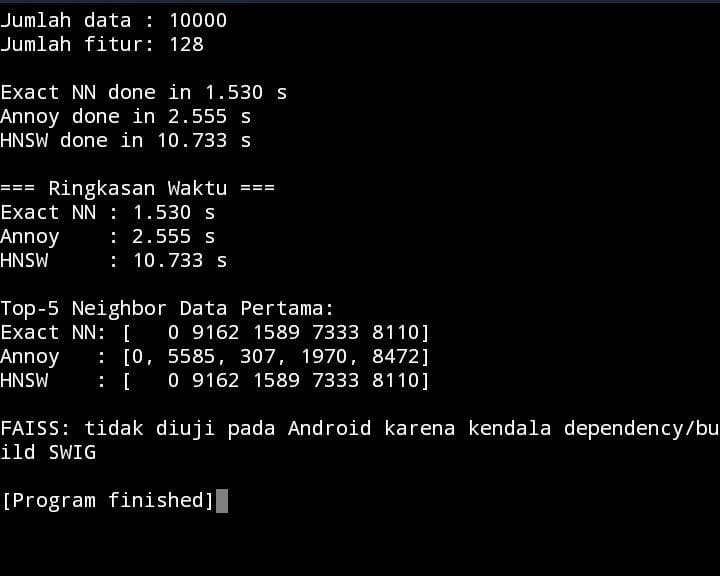

Langkah 3 - Mencatat Spesifikasi Smartphone

| Spesifikasi | Detail |
|---|---|
| Merek / Model | OPPO A5 Pro |
| Model Perangkat | CPH2711 |
| Processor | Qualcomm Snapdragon 6s 4G Gen 1 Octa-core |
| RAM | 8 GB + 8 GB RAM Expansion |
| Penyimpanan Internal | 128 GB |
| Penyimpanan Terpakai | 96,0 GB |
| Sistem Operasi | ColorOS / Android |
| Versi Perangkat Lunak | CPH2711_16.0.5.1201 (EX01B110P02) |
| Arsitektur | ARM64 / aarch64 |
| Environment Python | PyDroid3 |
| Versi Python | Python 3.13 |

Langkah 4 - Membandingkan Waktu Komputasi

| Model | Waktu Laptop | Waktu Android | Top-5 Neighbor Android |
|---|---:|---:|---|
| Exact NN | 1.358 s | 1.530 s | `[0, 9162, 1589, 7333, 8110]` |
| Annoy | 0.689 s | 2.555 s | `[0, 5585, 307, 1970, 8472]` |
| HNSW | 7.294 s | 10.733 s | `[0, 9162, 1589, 7333, 8110]` |
| FAISS IVF | 0.926 s | Tidak diuji | Tidak tersedia |

Berdasarkan hasil pengujian, waktu komputasi pada Android secara umum lebih lambat dibandingkan laptop. Exact NN membutuhkan waktu 1,530 detik di Android dan 1,358 detik di laptop. Annoy membutuhkan 2,555 detik di Android dan 0,689 detik di laptop, sedangkan HNSW membutuhkan 10,733 detik di Android dan 7,294 detik di laptop. Pada laptop, Annoy menjadi metode tercepat, sedangkan HNSW memiliki waktu komputasi paling lama. Dari sisi hasil pencarian, Exact NN dan HNSW menghasilkan Top-5 neighbor yang sama pada Android, sedangkan Annoy menghasilkan neighbor yang berbeda karena menggunakan pendekatan approximate. FAISS IVF tidak diuji pada Android karena kendala dependency dan proses build SWIG pada PyDroid3. Secara keseluruhan, performa ANN dipengaruhi tidak hanya oleh algoritma yang digunakan, tetapi juga oleh kemampuan perangkat dan dukungan library pada environment yang digunakan.